In [1]:
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import DecisionBoundaryDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error, roc_auc_score
from sklearn.model_selection import (
    GridSearchCV, KFold, StratifiedKFold, cross_val_score, train_test_split
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

Part A - KNN versus Gaussian naive Bayes

In [2]:
cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")
X_c = cancer.drop(columns=["id", "diagnosis", "Unnamed: 32"], errors="ignore")
y_c = (cancer["diagnosis"] == "M").astype(int)

Xc_train, Xc_valid, yc_train, yc_valid = train_test_split(
    X_c, y_c, test_size=0.25, random_state=42, stratify=y_c
)

k= 1 cross-validated ROC AUC 0.946
k= 3 cross-validated ROC AUC 0.984
k= 5 cross-validated ROC AUC 0.985
k= 7 cross-validated ROC AUC 0.987
k=11 cross-validated ROC AUC 0.988
k=21 cross-validated ROC AUC 0.988
selected k: 11


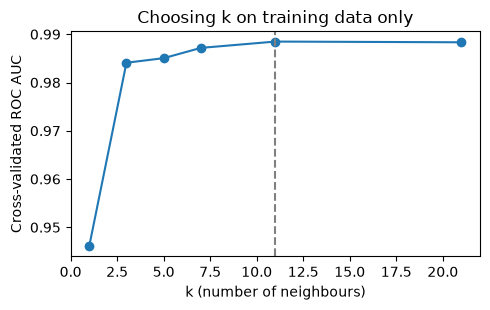

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
k_values = [1, 3, 5, 7, 11, 21]
cv_scores = {}

for k in k_values:
    candidate = Pipeline([
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k, weights="distance")),
    ])
    scores = cross_val_score(candidate, Xc_train, yc_train, cv=cv, scoring="roc_auc")
    cv_scores[k] = scores.mean()
    print(f"k={k:2d} cross-validated ROC AUC {scores.mean():.3f}")

best_k = max(cv_scores, key=cv_scores.get)
print("selected k:", best_k)

plt.figure(figsize=(5, 3.2))
plt.plot(k_values, [cv_scores[k] for k in k_values], marker="o")
plt.axvline(best_k, linestyle="--", color="grey")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Cross-validated ROC AUC")
plt.title("Choosing k on training data only")
plt.tight_layout()
plt.show()

In [4]:
models = {
    "KNN": Pipeline([
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=best_k, weights="distance")),
    ]),
    "GaussianNB": Pipeline([
        ("scale", StandardScaler()),
        ("model", GaussianNB()),
    ]),
}

for name, model in models.items():
    model.fit(Xc_train, yc_train)
    pred = model.predict(Xc_valid)
    prob_c = model.predict_proba(Xc_valid)[:, 1]
    print(f"{name:10s} accuracy={accuracy_score(yc_valid, pred):.3f} "
          f"roc_auc={roc_auc_score(yc_valid, prob_c):.3f}")

KNN        accuracy=0.958 roc_auc=0.986
GaussianNB accuracy=0.944 roc_auc=0.992


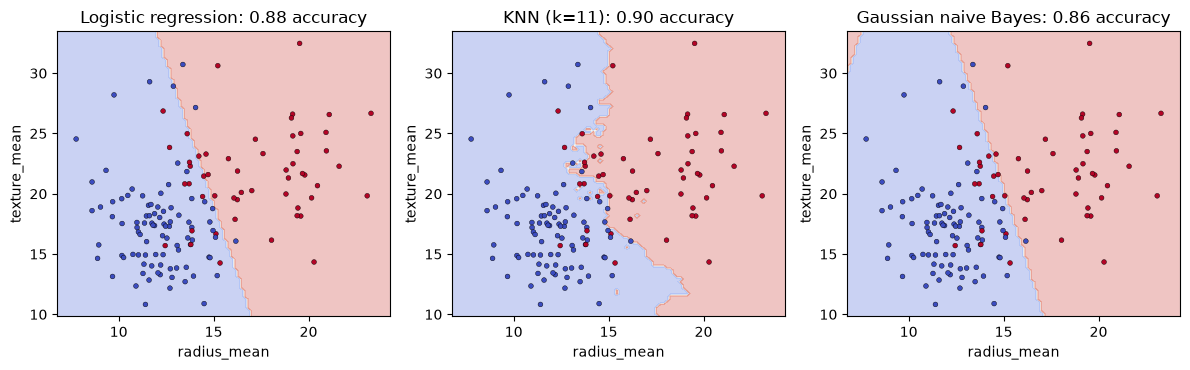

In [5]:
two = ["radius_mean", "texture_mean"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (name, estimator) in zip(axes, [
    ("Logistic regression", LogisticRegression(max_iter=2000)),
    (f"KNN (k={best_k})", KNeighborsClassifier(n_neighbors=best_k, weights="distance")),
    ("Gaussian naive Bayes", GaussianNB()),
]):
    small = Pipeline([("scale", StandardScaler()), ("model", estimator)])
    small.fit(Xc_train[two], yc_train)
    DecisionBoundaryDisplay.from_estimator(small, Xc_valid[two], ax=ax, alpha=0.3,
                                           response_method="predict", cmap="coolwarm")
    ax.scatter(Xc_valid[two[0]], Xc_valid[two[1]], c=yc_valid, cmap="coolwarm",
               s=12, edgecolor="k", linewidth=0.3)
    ax.set_title(f"{name}: {accuracy_score(yc_valid, small.predict(Xc_valid[two])):.2f} accuracy")
    ax.set_xlabel("radius_mean")
    ax.set_ylabel("texture_mean")

plt.tight_layout()
plt.show()

Part B - One readable decision tree, and what happens as it grows

In [6]:
titanic = pd.read_csv(DATA / "titanic_dataset.csv")
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
t_num = ["Age", "SibSp", "Parch", "Fare"]
t_cat = ["Pclass", "Sex", "Embarked"]

X_t = titanic[features]
y_t = titanic["Survived"]

tree_preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), t_num),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), t_cat),
])

Xt_train, Xt_valid, yt_train, yt_valid = train_test_split(
    X_t, y_t, test_size=0.25, random_state=42, stratify=y_t
)

tree = Pipeline([
    ("preprocess", tree_preprocess),
    ("tree", DecisionTreeClassifier(max_depth=4, min_samples_leaf=12, random_state=42)),
])

tree.fit(Xt_train, yt_train)
print("training accuracy:", round(accuracy_score(yt_train, tree.predict(Xt_train)), 3))
print("validation accuracy:", round(accuracy_score(yt_valid, tree.predict(Xt_valid)), 3))

training accuracy: 0.843
validation accuracy: 0.767


|--- cat__Sex_female <= 0.50
|   |--- num__Age <= 3.50
|   |   |--- class: 1
|   |--- num__Age >  3.50
|   |   |--- cat__Pclass_1 <= 0.50
|   |   |   |--- num__Fare <= 48.09
|   |   |   |   |--- class: 0
|   |   |   |--- num__Fare >  48.09
|   |   |   |   |--- class: 0
|   |   |--- cat__Pclass_1 >  0.50
|   |   |   |--- num__Age <= 53.00
|   |   |   |   |--- class: 0
|   |   |   |--- num__Age >  53.00
|   |   |   |   |--- class: 0
|--- cat__Sex_female >  0.50
|   |--- cat__Pclass_3 <= 0.50
|   |   |--- num__Fare <= 28.86
|   |   |   |--- num__Age <= 37.00
|   |   |   |   |--- class: 1
|   |   |   |--- num__Age >  37.00
|   |   |   |   |--- class: 1
|   |   |--- num__Fare >  28.86
|   |   |   |--- num__Parch <= 1.50
|   |   |   |   |--- class: 1
|   |   |   |--- num__Parch >  1.50
|   |   |   |   |--- class: 1
|   |--- cat__Pclass_3 >  0.50
|   |   |--- num__Fare <= 7.89
|   |   |   |--- cat__Embarked_S <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- cat__Embarked_S >  0.50
|   |

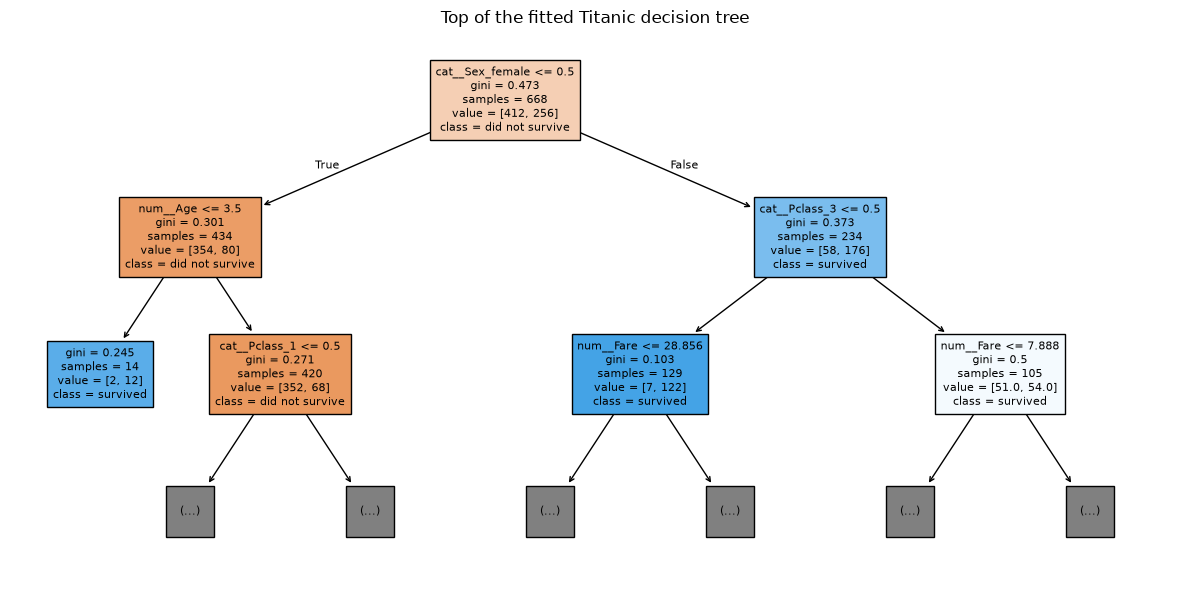

In [7]:
feature_names = list(tree.named_steps["preprocess"].get_feature_names_out())
print(export_text(tree.named_steps["tree"], feature_names=feature_names, max_depth=3))

plt.figure(figsize=(12, 6))
plot_tree(tree.named_steps["tree"], feature_names=feature_names,
          class_names=["did not survive", "survived"], max_depth=2, filled=True, fontsize=8)
plt.title("Top of the fitted Titanic decision tree")
plt.tight_layout()
plt.show()

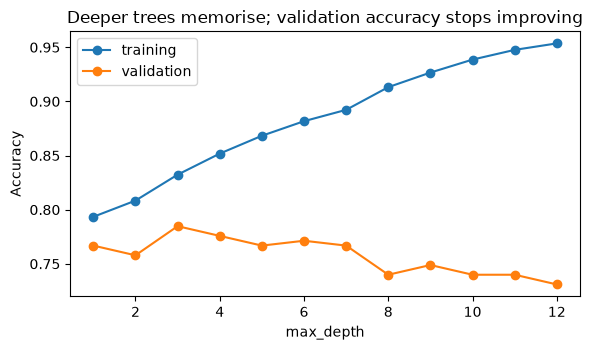

In [8]:
depths = list(range(1, 13))
train_acc, valid_acc = [], []

for depth in depths:
    t = Pipeline([
        ("preprocess", tree_preprocess),
        ("tree", DecisionTreeClassifier(max_depth=depth, random_state=42)),
    ]).fit(Xt_train, yt_train)
    train_acc.append(accuracy_score(yt_train, t.predict(Xt_train)))
    valid_acc.append(accuracy_score(yt_valid, t.predict(Xt_valid)))

plt.figure(figsize=(6, 3.6))
plt.plot(depths, train_acc, marker="o", label="training")
plt.plot(depths, valid_acc, marker="o", label="validation")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Deeper trees memorise; validation accuracy stops improving")
plt.legend()
plt.tight_layout()
plt.show()

Part C - Random forest versus gradient boosting

random_forest      CV log-RMSE 0.1382 +/- 0.0118
gradient_boosting  CV log-RMSE 0.1273 +/- 0.0141


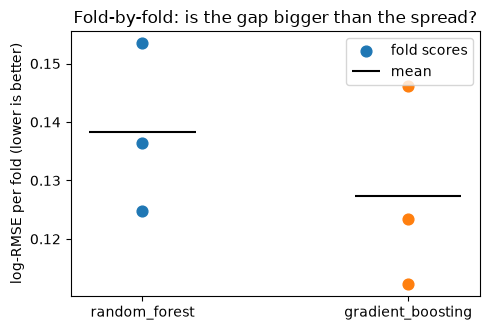

In [9]:
ames = pd.read_csv(DATA / "ames_housing_dataset.csv")
X_a = ames.drop(columns=["SalePrice", "Order", "PID"], errors="ignore")
y_a = np.log1p(ames["SalePrice"])

ames_preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), X_a.select_dtypes(include="number").columns),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), X_a.select_dtypes(exclude="number").columns),
])

ensembles = {
    "random_forest": RandomForestRegressor(
        n_estimators=150, max_features=0.8, min_samples_leaf=2, random_state=42, n_jobs=-1
    ),
    "gradient_boosting": GradientBoostingRegressor(
        n_estimators=150, learning_rate=0.05, max_depth=3, loss="huber", random_state=42
    ),
}

cv3 = KFold(n_splits=3, shuffle=True, random_state=42)
cv_rmse = {}

for name, estimator in ensembles.items():
    pipe = Pipeline([("preprocess", ames_preprocess), ("model", estimator)])
    neg_mse = cross_val_score(pipe, X_a, y_a, cv=cv3, scoring="neg_mean_squared_error")
    cv_rmse[name] = np.sqrt(-neg_mse)
    print(f"{name:18s} CV log-RMSE {cv_rmse[name].mean():.4f} +/- {cv_rmse[name].std():.4f}")

plt.figure(figsize=(5, 3.4))
for i, (name, values) in enumerate(cv_rmse.items()):
    plt.scatter([i] * len(values), values, s=60, label="fold scores" if i == 0 else None)
    plt.hlines(values.mean(), i - 0.2, i + 0.2, color="black", label="mean" if i == 0 else None)
plt.xticks(range(len(cv_rmse)), list(cv_rmse))
plt.ylabel("log-RMSE per fold (lower is better)")
plt.title("Fold-by-fold: is the gap bigger than the spread?")
plt.legend()
plt.tight_layout()
plt.show()

random_forest      MAE = 0.432 RMSE = 0.565
gradient_boosting  MAE = 0.476 RMSE = 0.597


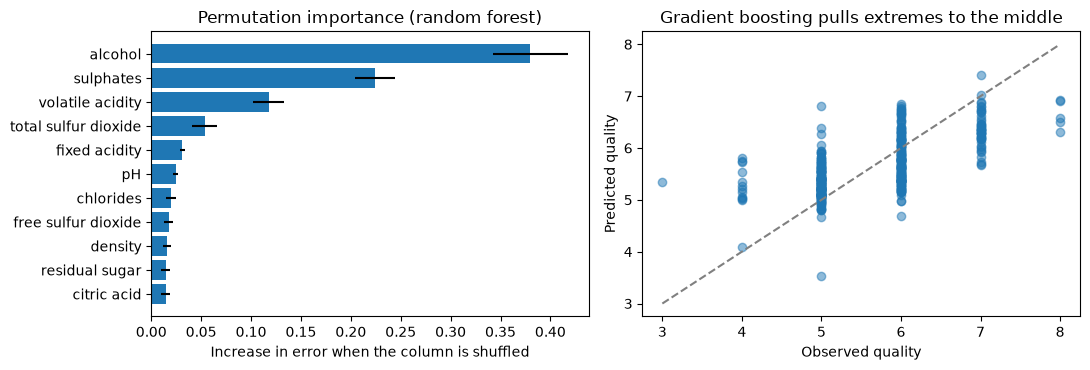

In [10]:
wine = pd.read_csv(DATA / "red_wine_quality_dataset.csv")
X_w = wine.drop(columns="quality")
y_w = wine["quality"]

Xw_train, Xw_valid, yw_train, yw_valid = train_test_split(X_w, y_w, test_size=0.25, random_state=42)

wine_models = {
    "random_forest": RandomForestRegressor(n_estimators=400, min_samples_leaf=2,
                                           random_state=42, n_jobs=-1),
    "gradient_boosting": GradientBoostingRegressor(random_state=42),
}

wine_pred = {}
for name, model in wine_models.items():
    model.fit(Xw_train, yw_train)
    wine_pred[name] = model.predict(Xw_valid)
    print(f"{name:18s} MAE = {mean_absolute_error(yw_valid, wine_pred[name]):.3f} "
          f"RMSE = {np.sqrt(mean_squared_error(yw_valid, wine_pred[name])):.3f}")

importance = permutation_importance(
    wine_models["random_forest"], Xw_valid, yw_valid, n_repeats=10, random_state=42, n_jobs=-1
)

ranked = pd.Series(importance.importances_mean, index=X_w.columns).sort_values()
spread = importance.importances_std[np.argsort(importance.importances_mean)]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].barh(ranked.index, ranked.values, xerr=spread)
axes[0].set_xlabel("Increase in error when the column is shuffled")
axes[0].set_title("Permutation importance (random forest)")
axes[1].scatter(yw_valid, wine_pred["gradient_boosting"], alpha=0.5)
axes[1].plot([3, 8], [3, 8], linestyle="--", color="grey")
axes[1].set_xlabel("Observed quality")
axes[1].set_ylabel("Predicted quality")
axes[1].set_title("Gradient boosting pulls extremes to the middle")
plt.tight_layout()
plt.show()

Part D - Support vector machines: two dials and a kernel

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X_c, y_c, test_size=0.25, random_state=42, stratify=y_c
)

svm_pipe = Pipeline([("scale", StandardScaler()), ("model", SVC())])

search = GridSearchCV(
    svm_pipe,
    param_grid={
        "model__kernel": ["linear", "rbf"],
        "model__C": [0.1, 1, 10, 100],
        "model__gamma": ["scale", 0.01, 0.1],
    },
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="roc_auc",
    n_jobs=-1,
)

search.fit(X_train, y_train)

score = search.decision_function(X_test)
pred = search.predict(X_test)

print("best parameters:", search.best_params_)
print("cross-validated ROC AUC:", round(search.best_score_, 3))
print("test accuracy:", round(accuracy_score(y_test, pred), 3))
print("test ROC AUC:", round(roc_auc_score(y_test, score), 3))

best parameters: {'model__C': 10, 'model__gamma': 0.01, 'model__kernel': 'rbf'}
cross-validated ROC AUC: 0.995
test accuracy: 0.979
test ROC AUC: 0.997


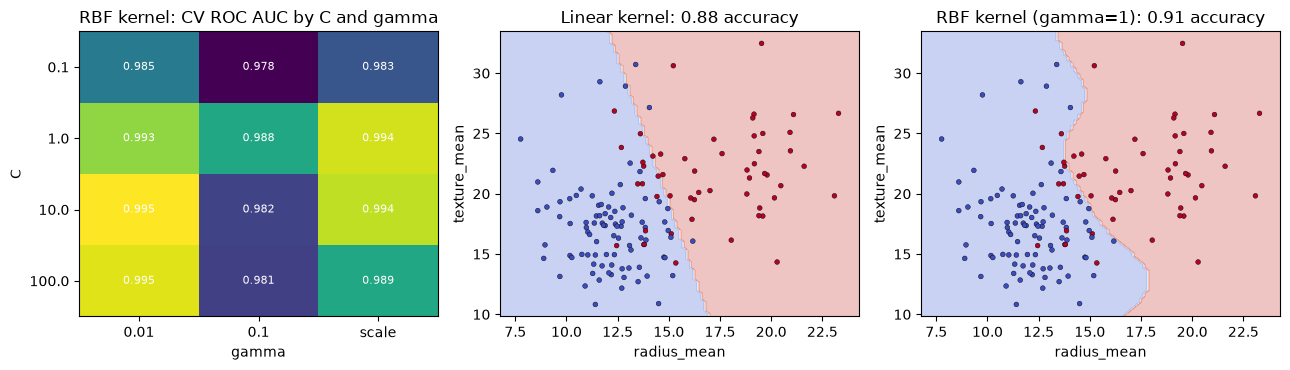

In [12]:
results = pd.DataFrame(search.cv_results_)
rbf = results[results["param_model__kernel"] == "rbf"].copy()
rbf["gamma"] = rbf["param_model__gamma"].astype(str)
grid = rbf.pivot(index="param_model__C", columns="gamma", values="mean_test_score")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

axes[0].imshow(grid.values, cmap="viridis", aspect="auto")
axes[0].set_xticks(range(len(grid.columns)), grid.columns)
axes[0].set_yticks(range(len(grid.index)), grid.index)
axes[0].set_xlabel("gamma")
axes[0].set_ylabel("C")

for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        axes[0].text(j, i, f"{grid.values[i, j]:.3f}", ha="center", va="center",
                     color="white", fontsize=8)

axes[0].set_title("RBF kernel: CV ROC AUC by C and gamma")

for ax, (title, estimator) in zip(axes[1:], [
    ("Linear kernel", SVC(kernel="linear", C=1)),
    ("RBF kernel (gamma=1)", SVC(kernel="rbf", C=1, gamma=1.0)),
]):
    small = Pipeline([("scale", StandardScaler()), ("model", estimator)]).fit(X_train[two], y_train)
    DecisionBoundaryDisplay.from_estimator(small, X_test[two], ax=ax, alpha=0.3,
                                           response_method="predict", cmap="coolwarm")
    ax.scatter(X_test[two[0]], X_test[two[1]], c=y_test, cmap="coolwarm",
               s=12, edgecolor="k", linewidth=0.3)
    ax.set_title(f"{title}: {accuracy_score(y_test, small.predict(X_test[two])):.2f} accuracy")
    ax.set_xlabel("radius_mean")
    ax.set_ylabel("texture_mean")

plt.tight_layout()
plt.show()

In [13]:
model_path = MODELS / "breast_cancer_svm.joblib"
joblib.dump(search.best_estimator_, model_path)

loaded = joblib.load(model_path)
same = np.array_equal(loaded.predict(X_test), pred)

print("file size (KB):", round(model_path.stat().st_size / 1024, 1))
print("reloaded model reproduces the test predictions:", same)

file size (KB): 16.5
reloaded model reproduces the test predictions: True


Try It Yourself

Task 1: Overgrown Titanic Decision Tree

In [14]:
unconstrained_tree = Pipeline([
    ("preprocess", tree_preprocess),
    ("tree", DecisionTreeClassifier(max_depth=None, min_samples_leaf=1, random_state=42)),
])
unconstrained_tree.fit(Xt_train, yt_train)

train_acc_unconstrained = accuracy_score(yt_train, unconstrained_tree.predict(Xt_train))
valid_acc_unconstrained = accuracy_score(yt_valid, unconstrained_tree.predict(Xt_valid))

train_acc_depth4 = accuracy_score(yt_train, tree.predict(Xt_train))
valid_acc_depth4 = accuracy_score(yt_valid, tree.predict(Xt_valid))

print("=== Titanic Tree Comparison ===")
print(f"Max Depth 4    -> Train Acc: {train_acc_depth4:.3f} | Valid Acc: {valid_acc_depth4:.3f}")
print(f"Unconstrained  -> Train Acc: {train_acc_unconstrained:.3f} | Valid Acc: {valid_acc_unconstrained:.3f}\n")

=== Titanic Tree Comparison ===
Max Depth 4    -> Train Acc: 0.843 | Valid Acc: 0.767
Unconstrained  -> Train Acc: 0.978 | Valid Acc: 0.722



This comparison provides an example of overfitting vs. proper generalization:

The Depth-4 tree balances bias and variance. By stopping early, it trades away a small amount of training accuracy to achieve better generalization on validation data.

The Unconstrained tree suffers from high variance. It memorizes specific outliers and noise unique to the training set rather than learning true underlying relationships, causing its performance on validation data to deteriorate significantly.

Try It Yourself

Task 2: Linear-only SVM Search

In [15]:
linear_svm_pipe = Pipeline([("scale", StandardScaler()), ("model", SVC())])

linear_search = GridSearchCV(
    linear_svm_pipe,
    param_grid={
        "model__kernel": ["linear"],
        "model__C": [0.1, 1, 10, 100],
    },
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="roc_auc",
    n_jobs=-1,
)
linear_search.fit(X_train, y_train)

linear_score = linear_search.decision_function(X_test)
linear_test_auc = roc_auc_score(y_test, linear_score)

print("=== SVM Search Comparison ===")
print(f"RBF/Grid Search Best Parameters : {search.best_params_}")
print(f"RBF/Grid Search Test ROC AUC    : {roc_auc_score(y_test, score):.3f}")
print(f"Linear-only Best Parameters    : {linear_search.best_params_}")
print(f"Linear-only Test ROC AUC       : {linear_test_auc:.3f}")

=== SVM Search Comparison ===
RBF/Grid Search Best Parameters : {'model__C': 10, 'model__gamma': 0.01, 'model__kernel': 'rbf'}
RBF/Grid Search Test ROC AUC    : 0.997
Linear-only Best Parameters    : {'model__C': 0.1, 'model__kernel': 'linear'}
Linear-only Test ROC AUC       : 0.997


Check Your Understanding

1.What is the geometric meaning of a larger separating margin in an SVM?
In SVMs, the separating margin is the Euclidean distance between the decision boundary (hyperplane) and the closest data points from either class (the support vectors). A larger margin means the decision boundary is placed as far away as possible from both classes, providing maximum geometric safety space and reducing the risk of misclassifying unseen data points that lie near the boundary.

2.How do C and, for an RBF kernel, γ change the flexibility of the fitted decision boundary?

CC (Regularization Parameter): Controls the tradeoff between achieving a smooth boundary and correctly classifying training points.

- A small CC allows more misclassifications (higher soft-margin tolerance), creating a simpler, smoother decision boundary (lower variance, higher bias).

- A large CC heavily penalizes misclassified points, forcing the boundary to bend and fit training points strictly (higher variance, potential overfitting).

γ (RBF Kernel Scale): Controls the radius of influence of individual support vectors.

- A small γ means a large influence radius; points far away impact the decision boundary, leading to a smoother, linear-like boundary.

- A large γ means a tight influence radius; only nearby points affect the boundary, creating complex, highly wiggly boundaries around specific clusters of training points (high risk of overfitting).

3.Why should scaling and SVM hyperparameter selection both happen inside the validation procedure?
To prevent data leakage:

- Scaling inside validation: Scaling parameters (like mean and standard deviation in StandardScaler) must be computed only from the training folds/splits. If you scale the full dataset beforehand, test set information leaks into the training pipeline.

- Hyperparameter selection inside validation: Hyperparameters (CC, \gammaγ, kernel) must be evaluated on internal validation folds (e.g., using GridSearchCV). Evaluating them on the final test set uses test set feedback to make modeling choices, resulting in overly optimistic error estimates.